<a href="https://colab.research.google.com/github/carlos1739/analisis_telco/blob/master/notebook/churn_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Project Identification

- **Judul:** Prediksi Churn Pelanggan Telekomunikasi
- **Domain:** *Customer Analytics* pada industri telekomunikasi
- **Stakeholder:** Pelanggan (*Customers*) dan Tim Manajemen Produk & Retensi
- **Sumber Data:** IBM Sample Data Sets (*Telco Customer Churn*), 7.043 pelanggan dan 21 atribut
- **Latar Belakang:** Mengapa mendeteksi pelanggan yang akan berhenti berlangganan itu penting bagi perusahaan telekomunikasi? Ada 3 faktor utama:
  1. Pendapatan utama perusahaan telekomunikasi bergantung pada stabilitas pelanggan berlangganan.
  2. Biaya mengakuisisi pelanggan baru jauh lebih mahal dibandingkan mempertahankan pelanggan yang sudah ada.
  3. Lebih baik mencegah secara proaktif daripada kehilangan pelanggan secara reaktif.


## 2. Problem Formulation

- **Problem:** Bagaimana memprediksi apakah seorang pelanggan akan *churn* (berhenti berlangganan) berdasarkan data demografi, layanan yang digunakan, dan informasi akun?
- **Jenis Tugas:** Klasifikasi Biner (*Supervised Learning*) — `Churn` (0 = tidak churn, 1 = churn)
- **Tujuan Analisis:**
  1. Mengidentifikasi faktor yang berasosiasi dengan *churn*, seperti jenis kontrak, lama berlangganan (*tenure*), biaya bulanan, dan jenis layanan internet.
  2. Menyiapkan data yang bersih dan fitur yang relevan sebagai fondasi untuk membangun model klasifikasi *churn*.
  3. Memberikan *insight* awal yang *actionable* (dapat ditindaklanjuti) untuk membantu strategi tim retensi.

### 3. Cleaning Data

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

print("library berhasil diimpor")

library berhasil diimpor


In [22]:
import pandas as pd
import zipfile
import urllib.request
from pathlib import Path

def load_telco_data():
    dataset_dir = Path("datasets")
    zip_path = dataset_dir / "Churn_Customer_telco.zip"
    csv_path = dataset_dir / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

    dataset_dir.mkdir(parents=True, exist_ok=True)

    if not zip_path.is_file():
        url = "https://github.com/carlos1739/analisis_telco/raw/master/data/Churn_Customer_telco.zip"
        urllib.request.urlretrieve(url, zip_path)

    if not csv_path.is_file():
        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(path=dataset_dir)

    return pd.read_csv(csv_path)

telco = load_telco_data()
display(telco.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [24]:
print("Shape:", telco.shape)
telco.info()

Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 n

In [38]:
telco.describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [39]:
# 1. Cek duplikat sebelum customerID dibuang
if "customerID" in telco.columns:
    print("Duplikat customerID   :", telco["customerID"].duplicated().sum())
    print("Duplikat seluruh baris:", telco.duplicated().sum())

# 2. TotalCharges: ubah ke numerik, lalu laporkan nilai kosong
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"].astype(str).str.strip(), errors="coerce")
kosong = telco["TotalCharges"].isnull()
print("\nTotalCharges kosong        :", kosong.sum())
print("Nilai tenure di baris itu  :", telco.loc[kosong, "tenure"].unique())

# 3. Isi 0 (belum pernah ditagih), bukan median
telco.loc[kosong, "TotalCharges"] = 0

# 4. Buang customerID (tidak dipakai sebagai fitur)
telco = telco.drop(columns=["customerID"], errors="ignore")

print("\nShape :", telco.shape)
print("Missing value total:", telco.isnull().sum().sum())
print(telco.dtypes)


TotalCharges kosong        : 0
Nilai tenure di baris itu  : []

Shape : (7043, 20)
Missing value total: 0
gender               object
SeniorCitizen        object
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [41]:
for col in telco.select_dtypes(exclude='number').columns:
    if col != "SeniorCitizen":
        telco[col] = telco[col].str.strip()

telco["MultipleLines"] = telco["MultipleLines"].replace("No phone service", "No")

for col in ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]:
    telco[col] = telco[col].replace("No internet service", "No")

telco["SeniorCitizen"] = telco["SeniorCitizen"].astype(object)

print(telco.shape)
for col in telco.select_dtypes(exclude='number').columns:
    print(f"{col}: {telco[col].unique()}")

(7043, 20)
gender: ['Female' 'Male']
SeniorCitizen: [0 1]
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes']
OnlineBackup: ['Yes' 'No']
DeviceProtection: ['No' 'Yes']
TechSupport: ['No' 'Yes']
StreamingTV: ['No' 'Yes']
StreamingMovies: ['No' 'Yes']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn: ['No' 'Yes']


In [42]:
display(telco.describe())

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


# Analisi EDA: Yohannes Cornelius Willifredi. s

## 4.1 Distribusi Target (`Churn`)

In [ ]:
print(telco.shape)
display(telco.head())

(7021, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Jumlah tiap kelas:
 Churn
No     5164
Yes    1857
Name: count, dtype: int64

Persentase tiap kelas:
 Churn
No     73.6
Yes    26.4
Name: proportion, dtype: float64


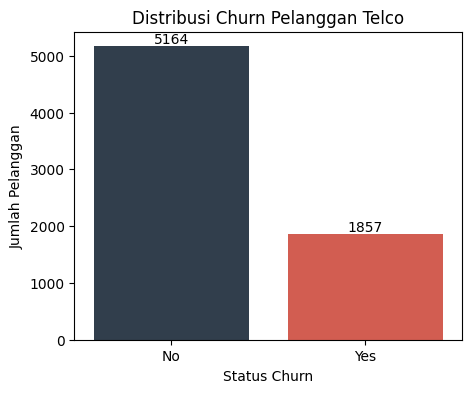

In [ ]:
print("Jumlah tiap kelas:\n", telco['Churn'].value_counts())
print("\nPersentase tiap kelas:\n", telco['Churn'].value_counts(normalize=True).round(3) * 100)

plt.figure(figsize=(5,4))
ax = sns.countplot(x='Churn', hue='Churn', data=telco, palette=['#2C3E50', '#E74C3C'], legend=False)
plt.title('Distribusi Churn Pelanggan Telco')
plt.xlabel('Status Churn')
plt.ylabel('Jumlah Pelanggan')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')

plt.show()

**catatan:** Dari 7.043 pelanggan, 1.869 (26,5%) churn dan 5.174 (73,5%) bertahan. Kelas target **tidak seimbang** (sekitar 3 : 1). Saat modeling, akurasi saja menyesatkan: model yang menebak "tidak churn" untuk semua pelanggan sudah mencapai 73,5%. Gunakan recall, precision, F1, atau PR-AUC, dan pertimbangkan `class_weight` atau resampling.

## 4.2 Analisis Univariat

### Fitur numerik

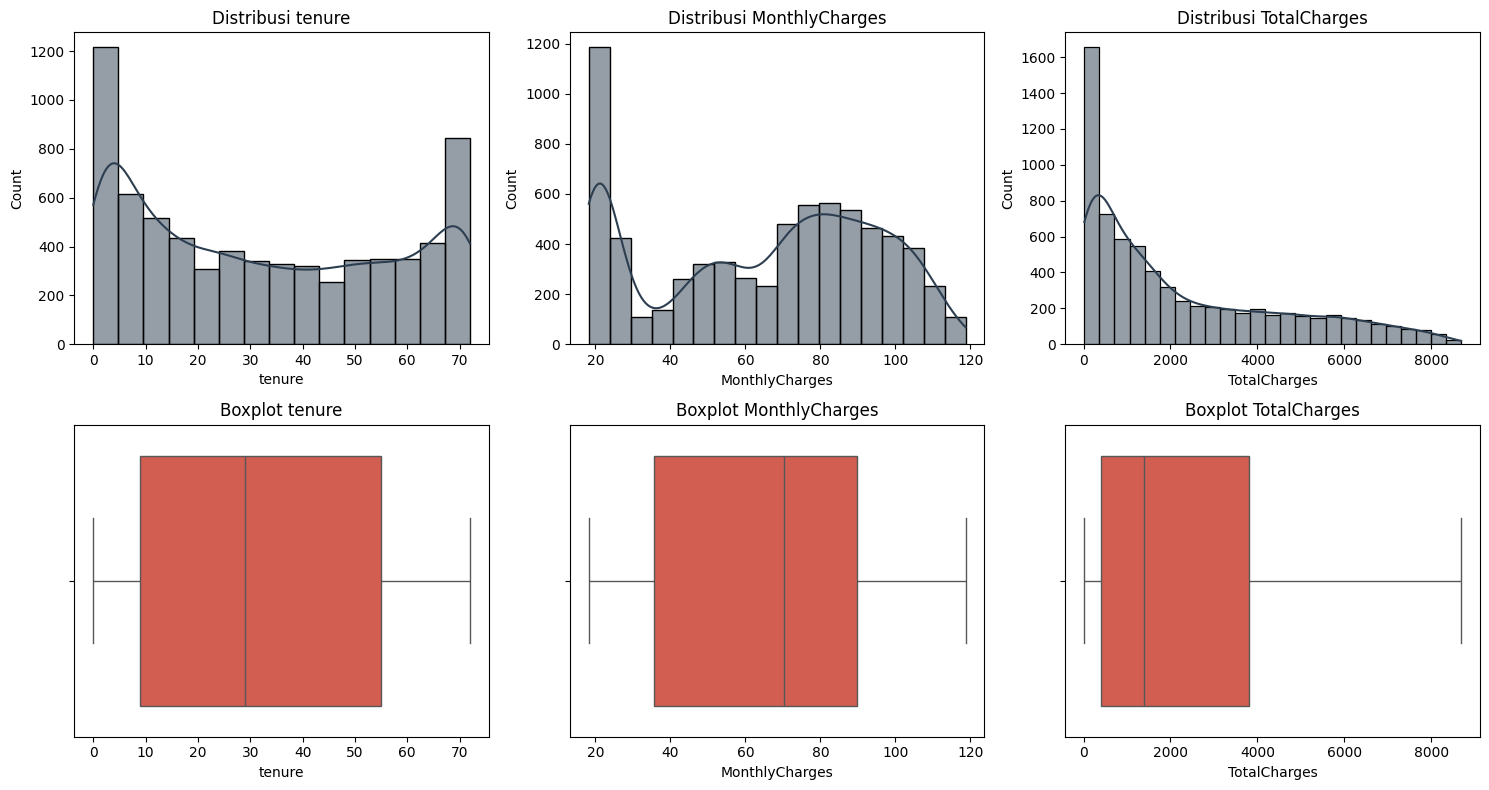

In [ ]:
fitur_numerik = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, kolom in enumerate(fitur_numerik):
    sns.histplot(telco[kolom], kde=True, ax=axes[0, i], color='#2C3E50')
    axes[0, i].set_title(f'Distribusi {kolom}')

    sns.boxplot(x=telco[kolom], ax=axes[1, i], color='#E74C3C')
    axes[1, i].set_title(f'Boxplot {kolom}')

plt.tight_layout()
plt.show()

In [59]:
fitur_numerik = ['tenure', 'MonthlyCharges', 'TotalCharges']
display(telco[fitur_numerik].agg(['mean', 'median', 'std', 'min', 'max', 'skew']).round(2))

,tenure,MonthlyCharges,TotalCharges
mean,32.37,64.76,2279.73
median,29.00,70.35,1394.55
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
max,72.00,118.75,8684.80
skew,0.24,-0.22,0.96


**Kesimpulan** **Diatas**:
- `tenure` hampir simetris (skew 0,24) tetapi punya dua puncak: banyak pelanggan baru (613 orang baru berlangganan 1 bulan) dan banyak pelanggan lama (362 orang di bulan ke-72, batas atas data).
- `MonthlyCharges` agak condong ke kiri (skew -0,22) dengan kelompok besar pelanggan berbiaya rendah (sekitar 23,5% membayar di bawah 30).
- `TotalCharges` condong ke kanan (skew 0,96) karena merupakan akumulasi tagihan. Transformasi log bisa dipertimbangkan saat modeling.

### Cek outlier (IQR)

In [ ]:
def cek_outlier_iqr(kolom):
    Q1 = telco[kolom].quantile(0.25)
    Q3 = telco[kolom].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR
    outlier = telco[(telco[kolom] < batas_bawah) | (telco[kolom] > batas_atas)]
    print(f"\nKolom: {kolom}")
    print(f"Batas bawah: {batas_bawah:.2f}, Batas atas: {batas_atas:.2f}")
    print(f"Jumlah outlier: {len(outlier)}")

for kolom in fitur_numerik:
    cek_outlier_iqr(kolom)


Kolom: tenure
Batas bawah: -60.00, Batas atas: 124.00
Jumlah outlier: 0

Kolom: MonthlyCharges
Batas bawah: -45.48, Batas atas: 171.12
Jumlah outlier: 0

Kolom: TotalCharges
Batas bawah: -4674.68, Batas atas: 8887.52
Jumlah outlier: 0


**Kesimpulan diatas :** Tidak ada outlier menurut aturan IQR pada ketiga fitur numerik, jadi tidak ada baris yang perlu dibuang atau di-*cap*. Nilai-nilai ekstrem seperti `tenure = 72` atau `TotalCharges` tinggi adalah nilai wajar, bukan kesalahan data.

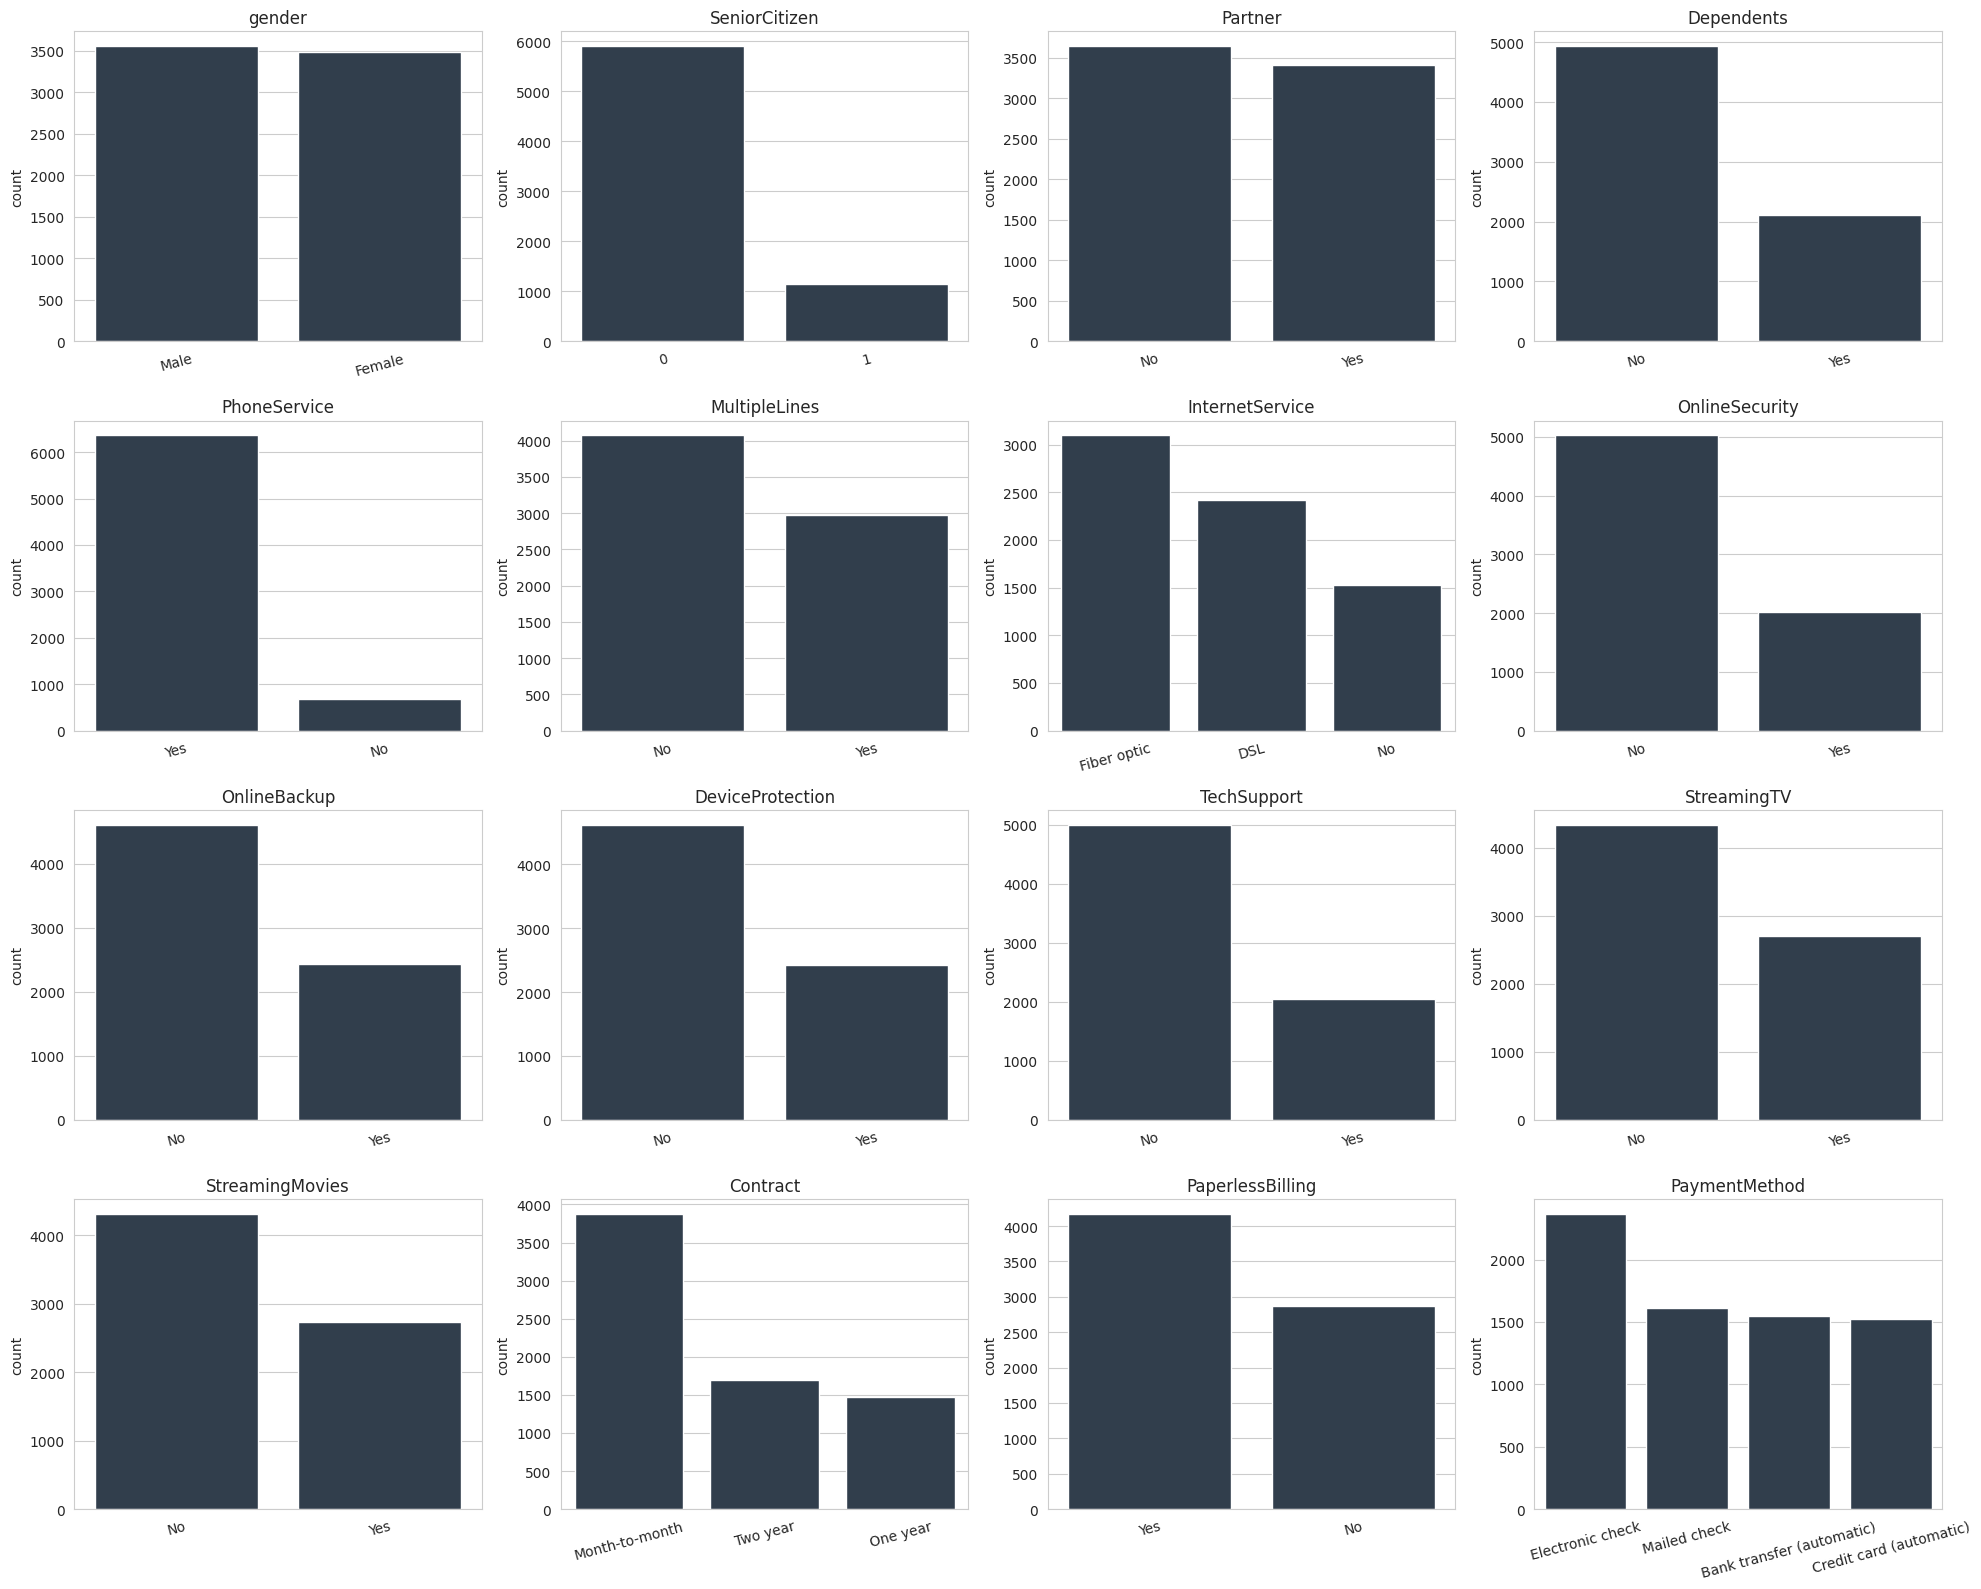

In [43]:
fitur_kategorikal = [c for c in telco.select_dtypes(exclude='number').columns if c != 'Churn']

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, kol in zip(axes.flat, fitur_kategorikal):
    urutan = telco[kol].value_counts().index
    sns.countplot(x=kol, data=telco, order=urutan, color='#2C3E50', ax=ax)
    ax.set_title(kol)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

**Kesimpulan di atas:** Sebagian besar kolom kategorikal biner. Perhatikan bahwa `PhoneService = No` adalah kelompok kecil, dan kategori "No" pada kolom layanan internet berisi gabungan pelanggan tanpa internet dan pelanggan yang memang tidak mengambil layanan itu. Distribusi `gender` hampir sama rata.

## 4.3 Analisis Bivariat: Fitur Numerik vs `Churn`

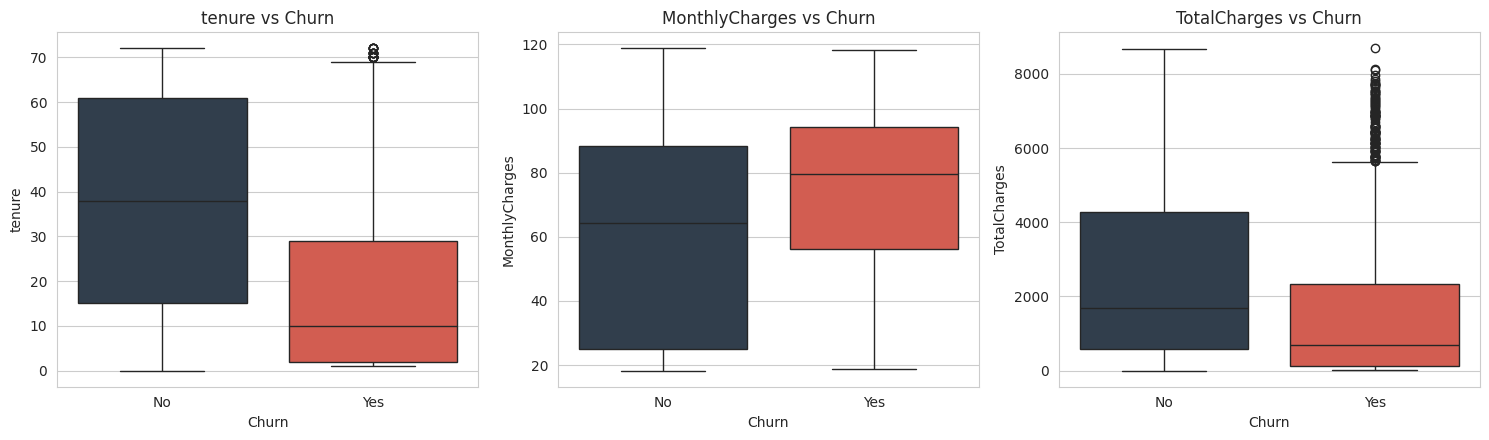

Ringkasan per status Churn:


tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55


Uji Mann-Whitney U (Churn=Yes vs No):
tenure          p-value = 2.420e-208
MonthlyCharges  p-value = 3.312e-54
TotalCharges    p-value = 5.685e-83


In [48]:
fitur_numerik = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, kol in zip(axes, fitur_numerik):
    sns.boxplot(x='Churn', y=kol, hue='Churn', data=telco,
                palette=['#2C3E50', '#E74C3C'], legend=False, ax=ax)
    ax.set_title(f'{kol} vs Churn')
plt.tight_layout()
plt.show()

print("Ringkasan per status Churn:")
display(telco.groupby('Churn')[fitur_numerik].agg(['mean', 'median']).round(2))

print("\nUji Mann-Whitney U (Churn=Ya vs Tidak):")
for kol in fitur_numerik:
    yes = telco.loc[telco['Churn'] == 'Yes', kol]
    no = telco.loc[telco['Churn'] == 'No', kol]
    stat, p = stats.mannwhitneyu(yes, no)
    print(f"{kol:15s} nilai p-value = {p:.3e}")

**Kesimpulan di atas :**
- Pelanggan churn punya `tenure` jauh lebih pendek (rata-rata 18,0 vs 37,6 bulan, median 10 vs 38).
- Pelanggan churn membayar `MonthlyCharges` lebih tinggi (rata-rata 74,4 vs 61,3).
- `TotalCharges` pelanggan churn lebih rendah (rata-rata 1.531,8 vs 2.549,9), terutama karena masa berlangganannya pendek.
- Ketiga perbedaan signifikan secara statistik (Mann-Whitney, p-value sangat kecil). Pola umumnya: pelanggan baru dengan tagihan bulanan tinggi paling rawan churn.

## 4.4 Analisis Bivariat: Fitur Kategorikal vs `Churn`

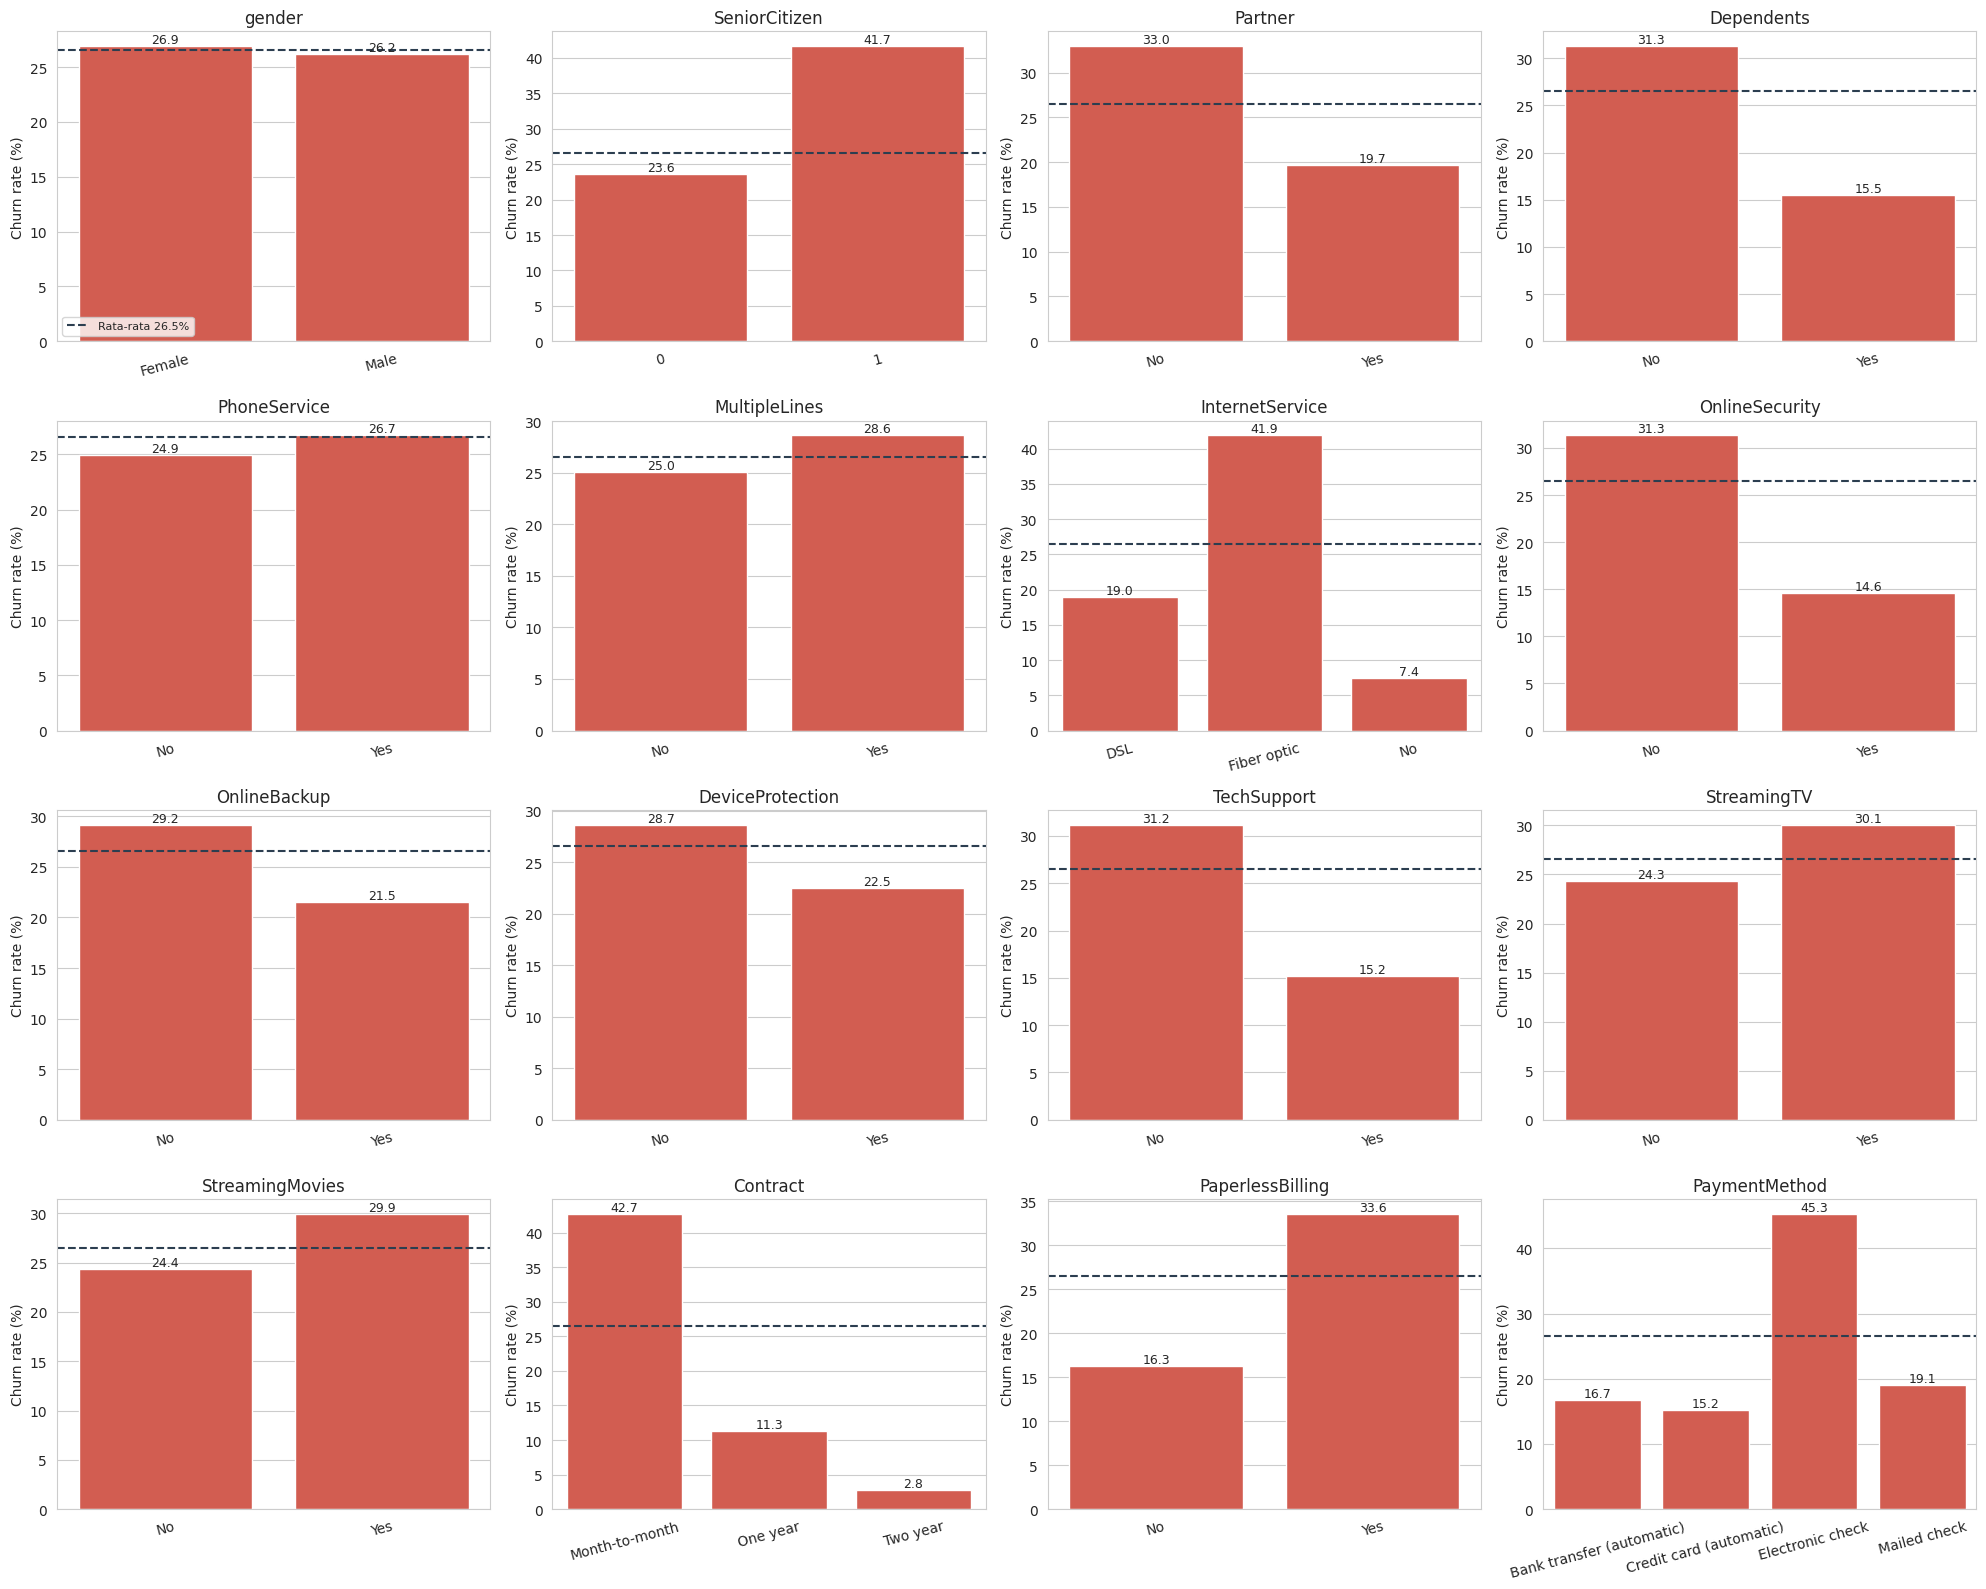

In [49]:
churn_rate_total = (telco['Churn'] == 'Yes').mean() * 100

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, kol in zip(axes.flat, fitur_kategorikal):
    rate = telco.groupby(kol)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
    sns.barplot(x=rate.index.astype(str), y=rate.values, color='#E74C3C', ax=ax)
    ax.axhline(churn_rate_total, ls='--', color='#2C3E50', label=f'Rata-rata {churn_rate_total:.1f}%')
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
    ax.set_title(kol)
    ax.set_xlabel('')
    ax.set_ylabel('Tingkat Churn (%)')
    ax.tick_params(axis='x', rotation=15)
axes.flat[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [60]:
# Peringkat fitur kategorikal: selisih churn rate tertinggi-terendah + kekuatan asosiasi (Cramér's V)
def cramers_v(x, y):
    tabel = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(tabel)
    n = tabel.values.sum()
    r, k = tabel.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), p

baris = []
for kol in fitur_kategorikal:
    rate = telco.groupby(kol)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
    v, p = cramers_v(telco[kol], telco['Churn'])
    baris.append({'fitur': kol, 'churn_rate_min': rate.min(), 'churn_rate_max': rate.max(),
                  'selisih': rate.max() - rate.min(), 'cramers_v': v, 'p_value': p})

peringkat = pd.DataFrame(baris).sort_values('cramers_v', ascending=False).round(3).reset_index(drop=True)
display(peringkat)

,fitur,churn_rate_min,churn_rate_max,selisih,cramers_v,p_value
0,Contract,2.832,42.710,39.878,0.410,0.000
1,InternetService,7.405,41.893,34.488,0.322,0.000
2,PaymentMethod,15.243,45.285,30.042,0.303,0.000
3,PaperlessBilling,16.330,33.565,17.235,0.191,0.000
4,OnlineSecurity,14.611,31.330,16.718,0.171,0.000
5,TechSupport,15.166,31.186,16.020,0.164,0.000
6,Dependents,15.450,31.279,15.829,0.164,0.000
7,SeniorCitizen,23.606,41.681,18.075,0.150,0.000
8,Partner,19.665,32.958,13.293,0.150,0.000
9,OnlineBackup,21.531,29.172,7.641,0.082,0.000


**Kesimpulan di atas:**
- Tiga fitur dengan asosiasi terkuat terhadap churn: **`Contract`** (Cramér's V 0,41), **`InternetService`** (0,32), dan **`PaymentMethod`** (0,30).
- Kontrak month-to-month churn 42,7% vs 2,8% untuk kontrak dua tahun.
- Pelanggan **fiber optic** churn 41,9%, jauh di atas DSL (19,0%) dan tanpa internet (7,4%).
- Pembayaran **electronic check** churn 45,3%, sedangkan metode lain 15-19%.
- Pelanggan tanpa `OnlineSecurity` atau `TechSupport` churn sekitar 31%, hampir dua kali lipat yang berlangganan (sekitar 15%). Kategori "No" di sini juga mencakup pelanggan tanpa internet, jadi efek sebenarnya perlu dilihat bersama `InternetService`.
- `SeniorCitizen` (41,7% vs 23,6%), `PaperlessBilling`, `Dependents`, dan `Partner` punya asosiasi sedang.
- `gender` (p = 0,487) dan `PhoneService` (p = 0,339) **tidak signifikan**, sehingga kandidat dibuang atau diberi bobot rendah saat seleksi fitur.

### Detail: Tipe Kontrak

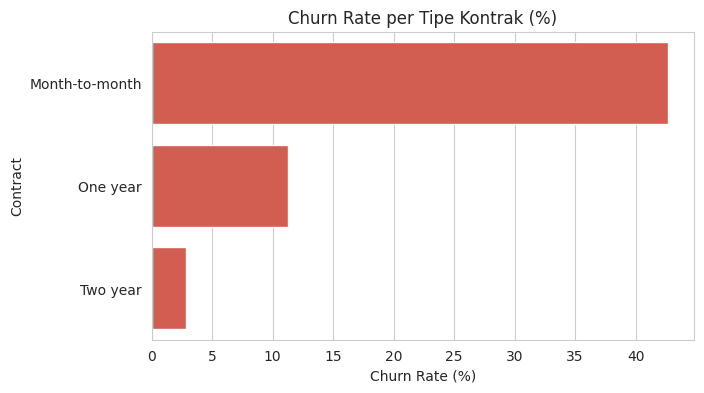

Churn rate per Contract (%):
 Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64

Rata-rata tenure per status Churn:
 Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

Rata-rata tenure per tipe Contract:
 Contract
Month-to-month    18.04
One year          42.04
Two year          56.74
Name: tenure, dtype: float64


In [52]:
churn_rate_contract = telco.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(7, 4))
sns.barplot(x=churn_rate_contract.values, y=churn_rate_contract.index, color='#E74C3C')
plt.title('Tingkat Churn per Tipe Kontrak (%)')
plt.xlabel('Tingkat Churn (%)')
plt.show()

print("Tingkat Churn per Kontrak (%):\n", churn_rate_contract.round(1))
print("\nRata-rata tenure per status Churn:\n", telco.groupby('Churn')['tenure'].mean().round(2))
print("\nRata-rata tenure per tipe Kontrak:\n", telco.groupby('Contract')['tenure'].mean().round(2))

## 4.5 Korelasi

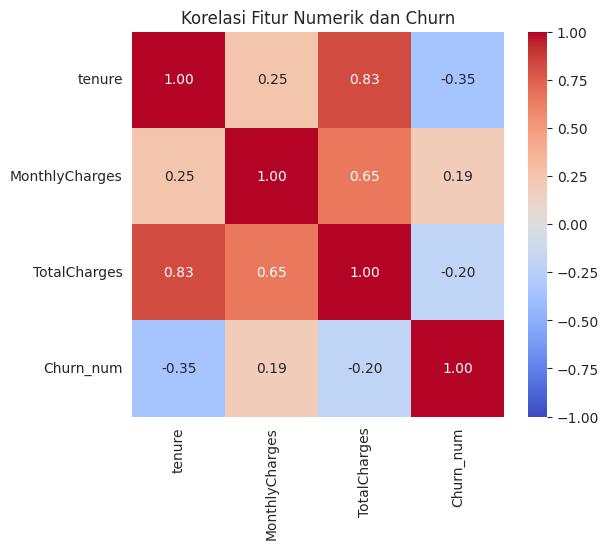

Korelasi TotalCharges vs (tenure x MonthlyCharges): 1.0


In [53]:
churn_num = (telco['Churn'] == 'Yes').astype(int).rename('Churn_num')
korelasi = pd.concat([telco[fitur_numerik], churn_num], axis=1).corr()

plt.figure(figsize=(6, 5))
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Korelasi Fitur Numerik dan Churn')
plt.show()

hampir = telco['tenure'] * telco['MonthlyCharges']
print("Korelasi TotalCharges vs (tenure x MonthlyCharges):", round(telco['TotalCharges'].corr(hampir), 3))

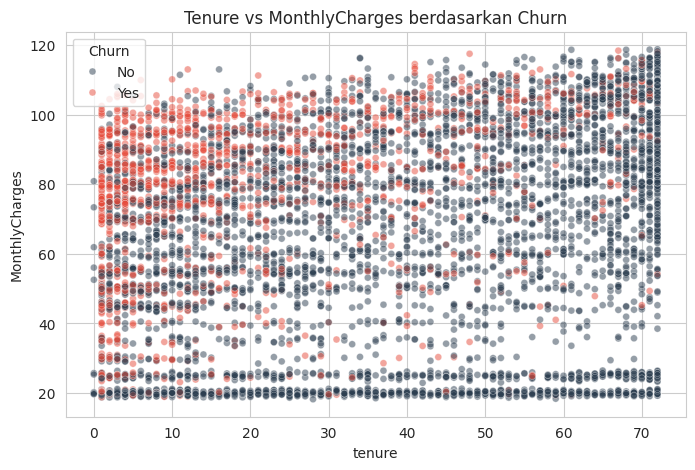

In [54]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='tenure', y='MonthlyCharges', hue='Churn', data=telco,
                palette=['#2C3E50', '#E74C3C'], alpha=0.5, s=25)
plt.title('Tenure vs Biaya Bulanan berdasarkan Churn')
plt.xlabel('Tenure (Bulan)')
plt.ylabel('Biaya Bulanan')
plt.show()

**Kesimpullan di atas:**
- `tenure` berkorelasi negatif dengan churn (-0,35): makin lama berlangganan, makin kecil peluang churn.
- `MonthlyCharges` berkorelasi positif lemah (0,19), `TotalCharges` negatif lemah (-0,20).
- `TotalCharges` sangat berkaitan dengan `tenure` (0,83) dan hampir identik dengan `tenure x MonthlyCharges` (korelasi 1,0). Ada **risiko multikolinearitas**, jadi untuk model linear pertimbangkan membuang `TotalCharges` atau memakai salah satunya saja.
- Scatterplot memperlihatkan titik churn menumpuk di area tenure rendah dan MonthlyCharges tinggi.

## 4.6 Analisis Multivariat

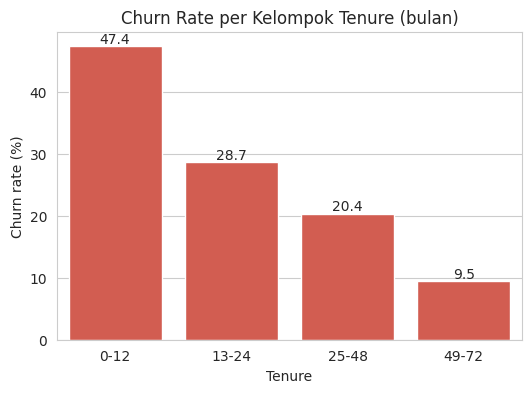

In [55]:
telco['tenure_group'] = pd.cut(telco['tenure'], bins=[-1, 12, 24, 48, 72],
                               labels=['0-12', '13-24', '25-48', '49-72'])
rate_tenure = telco.groupby('tenure_group', observed=True)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=rate_tenure.index.astype(str), y=rate_tenure.values, color='#E74C3C')
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.title('Tingkat Churn per Kelompok Tenure (bulan)')
plt.ylabel('Tingkat Churn (%)')
plt.xlabel('Tenure')
plt.show()

telco = telco.drop(columns='tenure_group')

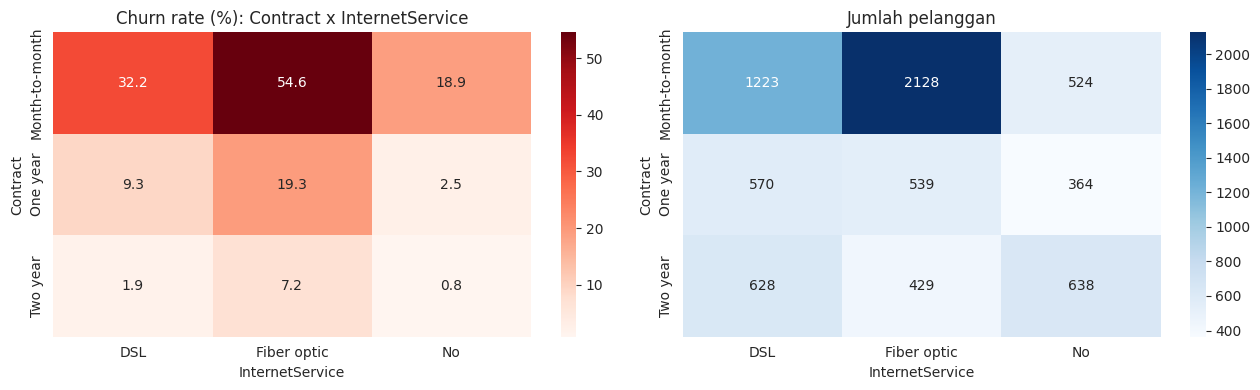

In [56]:
pivot_rate = pd.crosstab(telco['Contract'], telco['InternetService'],
                         values=(telco['Churn'] == 'Yes') * 100, aggfunc='mean')
pivot_n = pd.crosstab(telco['Contract'], telco['InternetService'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(pivot_rate, annot=True, fmt='.1f', cmap='Reds', ax=axes[0])
axes[0].set_title('Tingkat Churn (%): Kontrak x Layanan Internet')
axes[0].set_xlabel('Layanan Internet')
axes[0].set_ylabel('Kontrak')

sns.heatmap(pivot_n, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Jumlah Pelanggan')
axes[1].set_xlabel('Layanan Internet')
axes[1].set_ylabel('Kontrak')

plt.tight_layout()
plt.show()

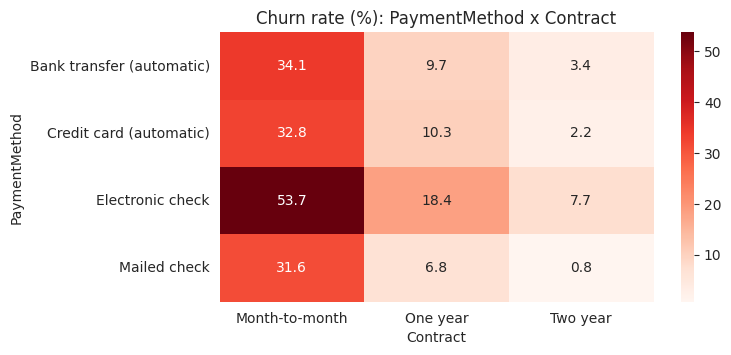

In [57]:
pivot_pay = pd.crosstab(telco['PaymentMethod'], telco['Contract'],
                        values=(telco['Churn'] == 'Yes') * 100, aggfunc='mean')
plt.figure(figsize=(7, 3.5))
sns.heatmap(pivot_pay, annot=True, fmt='.1f', cmap='Reds')
plt.title('Tingkat Churn (%): Metode Pembayaran x Kontrak')
plt.xlabel('Kontrak')
plt.ylabel('Metode Pembayaran')
plt.show()

**Kesimpulan di atas:**
- Churn rate turun tajam seiring tenure: **47,4%** (0-12 bulan), 28,7% (13-24), 20,4% (25-48), dan **9,5%** (49-72). Tahun pertama adalah periode paling kritis.
- Kombinasi paling berisiko: kontrak **month-to-month + fiber optic** dengan churn **54,6%** (2.128 pelanggan, kelompok terbesar). Kontrak dua tahun menekan churn di semua jenis internet (0,8% - 7,2%).
- Efek metode pembayaran bertahan di semua kontrak: **electronic check** selalu tertinggi (53,7% pada month-to-month, 18,4% pada one year, 7,7% pada two year).

# Kualitas Data & Perencanaan Fitur (bagian Engineer) : Radhit Maulana

In [ ]:
# Import Library dan Inisialisasi Data
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df_model = telco.copy()
print("Data awal berhasil disiapkan. Shape:", df_model.shape)

Data awal berhasil disiapkan. Shape: (7021, 20)


In [ ]:
# Feature Engineering

# Tenure Grouping (Mengelompokkan lama berlangganan)
def categorize_tenure(tenure):
    if tenure <= 12:
        return '0-1 Tahun'
    elif tenure <= 24:
        return '1-2 Tahun'
    elif tenure <= 48:
        return '2-4 Tahun'
    else:
        return '>4 Tahun'

df_model['TenureGroup'] = df_model['tenure'].apply(categorize_tenure)

# Total Services Used (Menghitung total layanan tambahan yang digunakan)
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

df_model['TotalServices'] = df_model[service_cols].apply(lambda x: (x == 'Yes').sum(), axis=1)

# Average Charges per Tenure (Rata-rata pengeluaran kumulatif)
df_model['AvgMonthlyPerTenure'] = np.where(df_model['tenure'] > 0, df_model['TotalCharges'] / df_model['tenure'], df_model['TotalCharges'])

print("Fitur baru berhasil dibuat!")
display(df_model[['tenure', 'TenureGroup', 'TotalServices', 'AvgMonthlyPerTenure']].head(3))

Fitur baru berhasil dibuat!


,tenure,TenureGroup,TotalServices,AvgMonthlyPerTenure
0,1,0-1 Tahun,1,29.850000
1,34,2-4 Tahun,3,55.573529
2,2,0-1 Tahun,3,54.075000


In [ ]:
# Encoding Variabel Kategorikal & Target

# # Ubah target 'Churn' ('Yes'/'No') menjadi 1/0
df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})

# Pisahkan fitur (X) dan target (y)
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

# One-Hot Encoding untuk variabel kategorikal
X_encoded = pd.get_dummies(X, drop_first=True)
print("Shape setelah One-Hot Encoding:", X_encoded.shape)

Shape setelah One-Hot Encoding: (7021, 28)


In [ ]:
# Feature Scaling
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices', 'AvgMonthlyPerTenure']

scaler = StandardScaler()
X_encoded[numerical_cols] = scaler.fit_transform(X_encoded[numerical_cols])

print("Scaling selesai. Contoh data numerik yang telah dinormalisasi:")
display(X_encoded[numerical_cols].head(3))

Scaling selesai. Contoh data numerik yang telah dinormalisasi:


,tenure,MonthlyCharges,TotalCharges,TotalServices,AvgMonthlyPerTenure
0,-1.282728,-1.164135,-0.997328,-1.150160,-0.611518
1,0.062387,-0.262811,-0.176347,-0.179691,-0.187834
2,-1.241967,-0.365914,-0.962760,-0.179691,-0.212516


In [ ]:
# Data Splitting (Train / Test Split 80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")
print(f"\nProporsi Churn pada y_train:\n{y_train.value_counts(normalize=True).round(3)}")

X_train shape: (5616, 28), y_train shape: (5616,)
X_test shape: (1405, 28), y_test shape: (1405,)

Proporsi Churn pada y_train:
Churn
0    0.736
1    0.264
Name: proportion, dtype: float64
